# Running MERlin's GenerateAdaptiveThreshold & AdaptiveFilterBarcodes on GS data
{
            "task": "GenerateAdaptiveThreshold",
            "module": "merlin.analysis.filterbarcodes",
            "parameters": {
                "decode_task": "Decode",
                "run_after_task": "Decode"
            }
        },
        {
            "task": "AdaptiveFilterBarcodes",
            "module": "merlin.analysis.filterbarcodes",
            "parameters": {
                "decode_task": "Decode",
                "adaptive_task": "GenerateAdaptiveThreshold"
            }
        },

## GenerateAdaptiveThreshold

In [1]:
# load raw decoded data 
# Modified from spotClasses_colocalisation.py load_spots_from_hdf5 function
import os
import pandas as pd
import h5py
import numpy as np

# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '..')


destination_folder = os.path.join(main_dir, 'Data/100uM/output/user_25FOVs_mag0_10_lc400_20240606_1743/coords_cache_BFS_assigned')
microscope_type = "Dory"

rows = []
def get_fov_from_filename(microscope_type, file: str):
    if microscope_type == "Triton":
        fov = '_'.join(file.split('_')[1:3])
    elif microscope_type == ("Dory" or 'Confocal'):
        fov = file.split('_')[1]
    return fov

coords_filelist = os.listdir(destination_folder)
for file in coords_filelist:
    fov = get_fov_from_filename(microscope_type, file)
    print(f"Loading spot metrics from FOV {fov}")
    coords_cache = os.path.join(destination_folder,file)
    print(coords_cache)
    with h5py.File(coords_cache, 'r') as f:
        for gene in f.keys():
            for spot in f[gene]:
                rows.append({
                    "zcoords": spot[0],
                    "ycoords": spot[1],
                    "xcoords": spot[2],
                    "fovs": fov,
                    "spot_sizes": spot[3],
                    "min_dists": spot[4],
                    "mean_intensities": spot[5],
                    "onoff_ratio1": spot[6],
                    "mindist2": spot[7],
                    "meaninten2": spot[8],
                    "onoff_ratio2": spot[9],
                    "mindist3": spot[10],
                    "meaninten3": spot[11],
                    "onoff_ratio3": spot[12],
                    "mindist1_2_ratio": spot[13],
                    "mindist1_3_ratio": spot[14],
                    "size_x": spot[15],
                    "size_y": spot[16],
                    "size_conn": spot[17],
                    "genes": gene,
                    "GS_bfs": spot[18],
                })

decoded_df = pd.DataFrame(rows)

Loading spot metrics from FOV 00
<main_dir>/Data/100uM/output/user_25FOVs_mag0_10_lc400_20240606_1743/coords_cache_BFS_assigned\FOV_00_coord_iter0.hdf5
Loading spot metrics from FOV 01
<main_dir>/Data/100uM/output/user_25FOVs_mag0_10_lc400_20240606_1743/coords_cache_BFS_assigned\FOV_01_coord_iter0.hdf5
Loading spot metrics from FOV 02
<main_dir>/Data/100uM/output/user_25FOVs_mag0_10_lc400_20240606_1743/coords_cache_BFS_assigned\FOV_02_coord_iter0.hdf5
Loading spot metrics from FOV 03
<main_dir>/Data/100uM/output/user_25FOVs_mag0_10_lc400_20240606_1743/coords_cache_BFS_assigned\FOV_03_coord_iter0.hdf5
Loading spot metrics from FOV 04
<main_dir>/Data/100uM/output/user_25FOVs_mag0_10_lc400_20240606_1743/coords_cache_BFS_assigned\FOV_04_coord_iter0.hdf5
Loading spot metrics from FOV 05
<main_dir>/Data/100uM/output/user_25FOVs_mag0_10_lc400_20240606_1743/coords_cache_BFS_assigned\FOV_05_coord_iter0.hdf5
Loading spot metrics from FOV 06
<main_dir>/Data/100uM/output/user_25FOVs_mag0_10_lc400_

In [2]:
decoded_df.head()

,zcoords,ycoords,xcoords,fovs,spot_sizes,min_dists,mean_intensities,onoff_ratio1,mindist2,meaninten2,...,mindist3,meaninten3,onoff_ratio3,mindist1_2_ratio,mindist1_3_ratio,size_x,size_y,size_conn,genes,GS_bfs
0,0.0,48.666667,1690.333333,00,3.0,0.532705,0.453084,0.141491,0.670101,0.440872,...,0.689771,0.438495,0.182677,0.794961,0.772293,2.0,2.0,1.0,1700017B05Rik,0.382452
1,0.0,57.500000,45.000000,00,2.0,0.487572,0.236930,0.052462,0.672749,0.226619,...,0.793266,0.132519,0.056229,0.724745,0.614638,2.0,1.0,1.0,1700017B05Rik,1.000000
2,0.0,61.500000,537.500000,00,4.0,0.325363,0.409348,0.171958,0.730230,0.325086,...,0.768680,0.317805,0.221665,0.445562,0.423275,2.0,2.0,1.0,1700017B05Rik,0.000000
3,0.0,66.250000,1539.000000,00,4.0,0.399159,0.420979,0.123191,0.687314,0.163465,...,0.732964,0.286246,0.146046,0.580752,0.544582,2.0,3.0,1.0,1700017B05Rik,0.160000
4,0.0,70.500000,1747.000000,00,2.0,0.416994,0.186627,0.032705,inf,0.000000,...,inf,0.000000,0.000000,0.000000,0.000000,2.0,1.0,1.0,1700017B05Rik,1.000000


## GenerateAdaptiveThreshold 

In [3]:
distance_threshold = 0.605 # follow original GS threshold


# initialize bins
# areaBins = np.arange(1, 35)
areaBins = np.array([2, 3, 4, 5, 10000])
distanceBins = np.linspace(0,decoded_df['min_dists'].max()+1e-2, 60) # np.arange(0, distance_threshold+0.02, 0.01)

for fov in decoded_df['fovs'].unique():
    fov_df = decoded_df[decoded_df['fovs'] == fov]

maxIntensity = np.log10(decoded_df['mean_intensities'].max())
intensityBins = np.logspace(-2, 1, int(60)) # np.arange(0, 2 * maxIntensity, maxIntensity / 100)

# initialize count arrays
blankCounts = np.zeros((len(intensityBins)-1,
                        len(distanceBins)-1,
                        len(areaBins)-1))
codingCounts = np.zeros((len(intensityBins)-1,
                        len(distanceBins)-1,
                        len(areaBins)-1))

In [4]:
def extract_counts(barcodes, intensityBins, distanceBins, areaBins):
    barcodeData = barcodes[['mean_intensities', 'min_dists', 'spot_sizes']].values
    barcodeData[:, 0] = np.log10(barcodeData[:, 0])
    return np.histogramdd(
        barcodeData, bins=(intensityBins, distanceBins, areaBins))[0]

In [5]:
blankCounts = extract_counts(decoded_df[decoded_df['genes'].str.contains(r'Blank', case=False, na=False)],
                             intensityBins, distanceBins, areaBins)
codingCounts = extract_counts(decoded_df[~decoded_df['genes'].str.contains(r'Blank', case=False, na=False)],
                             intensityBins, distanceBins, areaBins)

## AdaptiveFilterBarcodes

In [ ]:
from scipy import optimize

tolerance = 0.001
targetMisidentificationRate = 0.05
num_blanks = 7
num_valid_barcodes = len(decoded_df['genes'].unique()) - num_blanks
result_store = {}

def calculate_misidentification_rate_for_threshold(threshold, num_blanks, num_codes, blankHistogram, codingHistogram,
                                                   store=None):
        blankBarcodeCount = num_blanks
        codingBarcodeCount = num_codes
        # original ver blankFraction : 
        # blankFraction = blankHistogram / codingHistogram # from def get_blank_fraction_histogram(self)
        # blankFraction[codingHistogram == 0] = np.finfo(blankFraction.dtype).max # if no valid barcodes, set blank fraction to max (worst score)
        blankFraction = blankHistogram / (codingHistogram + blankHistogram)
        blankFraction[(codingHistogram + blankHistogram) == 0] = np.finfo(blankFraction.dtype).max
        blankFraction /= blankBarcodeCount/(blankBarcodeCount + codingBarcodeCount) # normalize fraction
        selectBins = blankFraction < threshold
        codingCounts = np.sum(codingHistogram[selectBins])
        blankCounts = np.sum(blankHistogram[selectBins])
        misidrate = (blankCounts / blankBarcodeCount) / (codingCounts / codingBarcodeCount) #misidentification rate! 
        if store is not None:
                store["blankFraction"] = blankFraction
                store["last_threshold"] = threshold
        return misidrate


def misidentification_rate_error_for_threshold(x, targetError, num_blanks, num_valid_barcodes, blankHistogram, codingHistogram, store):
        rate = calculate_misidentification_rate_for_threshold(
        x, num_blanks, num_valid_barcodes,
        blankHistogram, codingHistogram,
        store=store)
        return rate - targetError


# Run 
threshold = optimize.newton(
            misidentification_rate_error_for_threshold, 0.2,
            args=[targetMisidentificationRate, num_blanks, 
                  num_valid_barcodes, blankCounts, codingCounts,
                  result_store], tol=tolerance, x1=0.3,
            disp=False)

<user_home>\AppData\Local\Temp\ipykernel_34744\2499545759.py:16: RuntimeWarning: invalid value encountered in divide
  blankFraction = blankHistogram / (codingHistogram + blankHistogram)
<user_home>\AppData\Local\Temp\ipykernel_34744\2499545759.py:18: RuntimeWarning: overflow encountered in divide
  blankFraction /= blankBarcodeCount/(blankBarcodeCount + codingBarcodeCount) # normalize fraction
<user_home>\miniforge-pypy3\envs\GS_JZ_new\lib\site-packages\scipy\optimize\_zeros_py.py:348: RuntimeWarning: Tolerance of 0.004629670181636292 reached.
  warnings.warn(msg, RuntimeWarning)


In [14]:
print(threshold) #original blankFraction: 0.8336884369334662

0.7575823878674712


In [8]:
# modified from def extract_barcodes_with_threshold
selectData = decoded_df[['mean_intensities', 'min_dists', 'spot_sizes']].to_numpy()
blankFraction = result_store["blankFraction"]

barcodeBins = np.array((np.digitize(selectData[:, 0], intensityBins,right=True),
                        np.digitize(selectData[:, 1], distanceBins,right=True),
                         np.digitize(selectData[:, 2], areaBins))) - 1
barcodeBins[0, :] = np.clip(barcodeBins[0, :], 0, blankFraction.shape[0]-1)
barcodeBins[1, :] = np.clip(barcodeBins[1, :], 0, blankFraction.shape[1]-1)
barcodeBins[2, :] = np.clip(barcodeBins[2, :], 0, blankFraction.shape[2]-1)

thresholdedBlankFraction = blankFraction < threshold #blankThreshold

In [9]:
thresholdedBlankFraction.shape

(59, 59, 4)

In [10]:
decoded_df['adaptive_score'] = blankFraction[barcodeBins[0],barcodeBins[1],barcodeBins[2]]
decoded_df['pass_threshold'] = thresholdedBlankFraction[
    barcodeBins[0],
    barcodeBins[1],
    barcodeBins[2]
]

In [11]:
# save as h5 using h5py
df = decoded_df

with h5py.File("LM39CELLMERlinAdaptiveFilter_result_matchGS_everything.h5", "w") as f:
    for col in df.columns:
        data = df[col].to_numpy()

        # handle strings separately
        if data.dtype == object:
            data = data.astype("S")  # or "utf-8" handling below

        f.create_dataset(col, data=data)

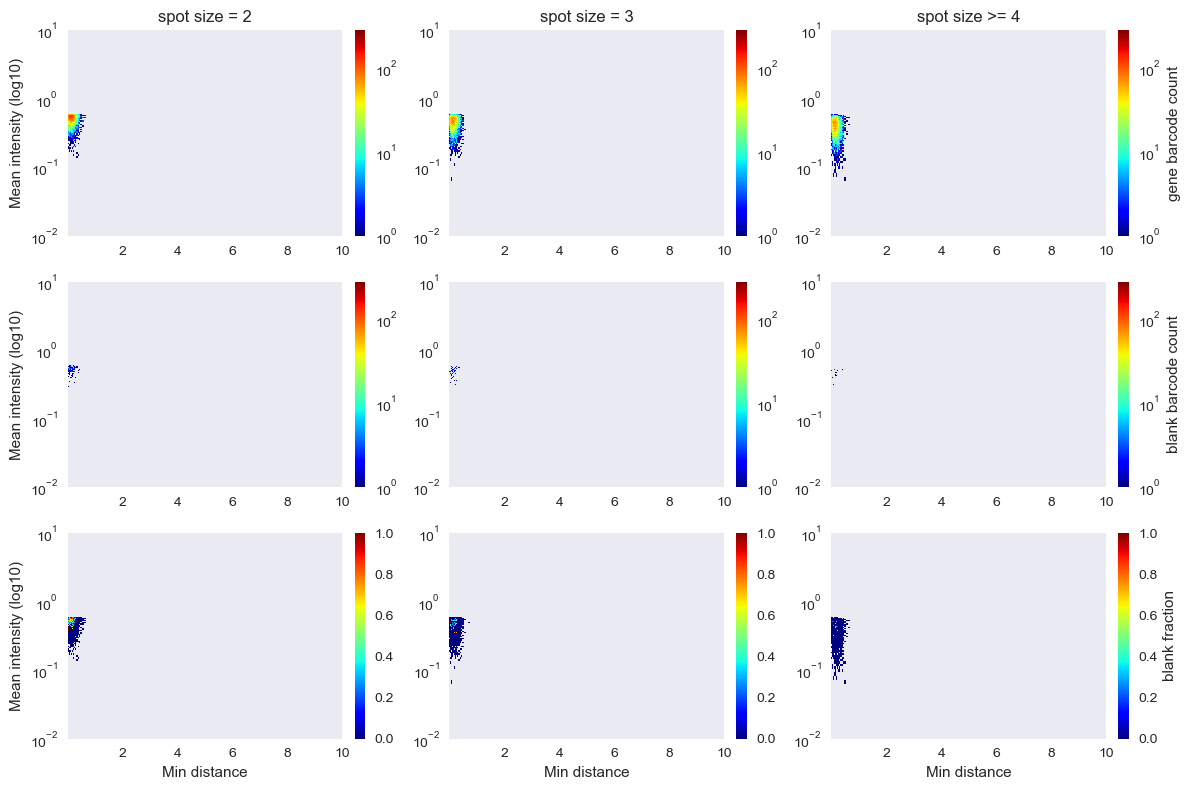

In [12]:
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.style.use('seaborn')
num_size_bins = codingCounts.shape[2]
ybins = distanceBins
xbins = intensityBins
plt.rcParams['figure.figsize'] = [4*(num_size_bins-1),8]
fig, ax = plt.subplots(3, num_size_bins-1)
vmax = codingCounts.max()
blank_fraction_vmax = 1

for i in range(num_size_bins-1):
    im = ax[0,i].pcolormesh(xbins, ybins, codingCounts[:,:,i].T, norm=mpl.colors.LogNorm(vmax=vmax),
                            cmap='jet')
    cb = plt.colorbar(im, ax=ax[0,i], fraction=0.046, pad=0.04)
    if i == num_size_bins-2:
        cb.set_label(label="gene barcode count")
    im = ax[1,i].pcolormesh(xbins, ybins, blankCounts[:,:,i].T, norm=mpl.colors.LogNorm(vmax=vmax),
                            cmap='jet')
    cb = plt.colorbar(im, ax=ax[1,i], fraction=0.046, pad=0.04)
    if i == num_size_bins-2:
        cb.set_label(label="blank barcode count")
    im = ax[2,i].pcolormesh(xbins, ybins, blankFraction[:,:,i].T, vmin=0, vmax=blank_fraction_vmax, cmap='jet')
    cb = plt.colorbar(im, ax=ax[2,i], fraction=0.046, pad=0.04)
    if i == num_size_bins-2:
        cb.set_label(label="blank fraction")

    ax[0,i].set_xlim([xbins[0],xbins[-1]])
    ax[0,i].set_ylim([1e-2,1e1])
    ax[0,i].set_yscale('log')
    ax[1,i].set_xlim([xbins[0],xbins[-1]])
    ax[1,i].set_ylim([1e-2,1e1])
    ax[1,i].set_yscale('log')
    ax[2,i].set_xlim([xbins[0],xbins[-1]])
    ax[2,i].set_ylim([1e-2,1e1])
    ax[2,i].set_yscale('log')
    ax[2,i].set_xlabel("Min distance")
    if i == num_size_bins-2:
        ax[0,i].set_title(f"spot size >= {areaBins[i]}")
    else:
        ax[0,i].set_title(f"spot size = {areaBins[i]}")
    if i == 0:
        ax[0,0].set_ylabel('Mean intensity (log10)')
        ax[1,0].set_ylabel('Mean intensity (log10)')
        ax[2,0].set_ylabel('Mean intensity (log10)')
    plt.tight_layout()
plt.show()